In [1]:
import pandas as pd

df = pd.read_csv('../dados/datatran2025.csv', sep=';', encoding='latin1')
df.head()


,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,...,feridos_graves,ilesos,ignorados,feridos,veiculos,latitude,longitude,regional,delegacia,uop
0,652493,2025-01-01,quarta-feira,06:20:00,SP,116,225,GUARULHOS,Reação tardia ou ineficiente do condutor,Tombamento,...,0,0,1,1,2,"-23,48586772","-46,54075317",SPRF-SP,DEL01-SP,UOP01-DEL01-SP
1,652519,2025-01-01,quarta-feira,07:50:00,CE,116,"546,2",PENAFORTE,Pista esburacada,Colisão frontal,...,0,1,4,1,6,"-7,812288","-39,08333306",SPRF-CE,DEL05-CE,UOP03-DEL05-CE
2,652522,2025-01-01,quarta-feira,08:45:00,PR,369,"88,2",CORNELIO PROCOPIO,Reação tardia ou ineficiente do condutor,Colisão traseira,...,0,2,0,3,2,"-23,182565","-50,637228",SPRF-PR,DEL07-PR,UOP05-DEL07-PR
3,652544,2025-01-01,quarta-feira,11:00:00,PR,116,74,CAMPINA GRANDE DO SUL,Reação tardia ou ineficiente do condutor,Saída de leito carroçável,...,0,4,0,1,2,"-25,36517687","-49,04223028",SPRF-PR,DEL01-PR,UOP02-DEL01-PR
4,652549,2025-01-01,quarta-feira,09:30:00,MG,251,471,FRANCISCO SA,Velocidade Incompatível,Colisão frontal,...,1,1,2,2,4,"-16,46801304","-43,43121303",SPRF-MG,DEL12-MG,UOP01-DEL12-MG


In [34]:
# importar bibliotecas de visualização
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Verificar valores faltantes em cada coluna, com objetivo de identicar problemas com a base de dados.

df.isna().sum()


id                         0
data_inversa               0
dia_semana                 0
horario                    0
uf                         0
br                         0
km                         0
municipio                  0
causa_acidente             0
tipo_acidente              0
classificacao_acidente     1
fase_dia                   0
sentido_via                0
condicao_metereologica     0
tipo_pista                 0
tracado_via                0
uso_solo                   0
pessoas                    0
mortos                     0
feridos_leves              0
feridos_graves             0
ilesos                     0
ignorados                  0
feridos                    0
veiculos                   0
latitude                   0
longitude                  0
regional                   2
delegacia                 22
uop                       38
dtype: int64

In [4]:
# Para tratar os valores faltantes, vamos preencher os compos com "não informado".

df['classificacao_acidente'] = df['classificacao_acidente'].fillna('não informado')
df['regional'] = df['regional'].fillna('não informado')
df['delegacia'] = df['delegacia'].fillna('não informado')
df['uop'] = df['uop'].fillna('não informado')

In [5]:
# Verificando o comando se deu certo

df[['classificacao_acidente', 'regional', 'delegacia', 'uop']].isna().sum()

classificacao_acidente    0
regional                  0
delegacia                 0
uop                       0
dtype: int64

In [6]:
# Verificar a existência de informações duplicadas

df.duplicated().sum()

np.int64(0)

In [7]:
# Convertendo colunas de Data e números para os tipos corretos

# Convertendo datas
df['data_inversa'] = pd.to_datetime(df['data_inversa'], errors='coerce')

# Convertendo quilometragem
df['km'] = pd.to_numeric(df['km'], errors='coerce')

In [8]:
# Conferindo os tipos das colunas após a conversão

df.dtypes[['data_inversa', 'km']]

data_inversa    datetime64[us]
km                     float64
dtype: object

In [9]:
# Corrigindo acentuação e padronizando os valores das colunas para evitar duplicidade por causa de diferenças de acentuação ou caixa alta/baixa.

df['tipo_acidente'] = df['tipo_acidente'].str.strip().str.lower()
df['causa_acidente'] = df['causa_acidente'].str.strip().str.lower()

## 🧹 Tratamento da coluna `km` — Identificação do problema e justificativa

Durante o processo de limpeza da base, foi identificado que a coluna **`km`** apresenta **26.675 valores faltantes**. Esse comportamento é comum em bases da Polícia Rodoviária Federal (PRF) e ocorre por diversos motivos operacionais.

### 🔍 Identificação do problema
A coluna `km` contém uma quantidade significativa de valores ausentes (NaN), indicando que muitos registros de acidentes não possuem a informação de quilometragem.

### 🛑 Causas prováveis para o problema
As causas mais comuns para ausência de quilometragem são:

- Trechos de rodovia **sem marcação de km**.
- Acidentes ocorridos em **perímetros urbanos** de BRs, onde o km não é registrado.
- **Erros ou omissões** no preenchimento do boletim de ocorrência.
- Registros feitos em situações emergenciais, onde a prioridade é o atendimento e não a coleta completa de dados.

Esses fatores tornam a ausência de km um comportamento esperado na base da PRF.

### 📊 Impacto nas análises propostas
As análises realizadas neste projeto **não dependem da coluna `km`**, pois tratam de:

- tipos de acidentes  
- distribuição por estado  
- vítimas  
- causas  
- condições da via  

Nenhuma dessas análises utiliza a quilometragem como variável explicativa ou de agrupamento.

Portanto, a ausência de valores em `km` **não compromete a qualidade nem a interpretação dos resultados**.

### ✔️ Decisão tomada
Optou-se por **manter os valores ausentes (NaN)** na coluna `km`, pois:

- representam ausência legítima de informação;  
- não interferem nas análises propostas;  
- evitam distorções que poderiam surgir ao preencher com valores artificiais.

Essa decisão é documentada para garantir transparência e rastreabilidade no processo de limpeza da base.

In [10]:
# Conferindo se foram tratadas todas as informações ou se ainda existem inconsistências

df.isna().sum(), df.duplicated().sum()

(id                            0
 data_inversa                  0
 dia_semana                    0
 horario                       0
 uf                            0
 br                            0
 km                        26675
 municipio                     0
 causa_acidente                0
 tipo_acidente                 0
 classificacao_acidente        0
 fase_dia                      0
 sentido_via                   0
 condicao_metereologica        0
 tipo_pista                    0
 tracado_via                   0
 uso_solo                      0
 pessoas                       0
 mortos                        0
 feridos_leves                 0
 feridos_graves                0
 ilesos                        0
 ignorados                     0
 feridos                       0
 veiculos                      0
 latitude                      0
 longitude                     0
 regional                      0
 delegacia                     0
 uop                           0
 dtype: in

# 🛠️ Criação de colunas derivadas
**Objetivo:** criar colunas auxiliares das análises

In [30]:
# Coluna que mostra o período do dia de acordo com a hora do acidente

def periodo_dia(hora):
    if 5 <= hora < 12:
        return 'manhã'
    elif 12 <= hora < 18:
        return 'tarde'
    elif 18 <= hora < 24:
        return 'noite'
    else:
        return 'madrugada'

df['hora'] = pd.to_datetime(df['horario'], errors='coerce').dt.hour
df['periodo_dia'] = df['hora'].apply(periodo_dia)

df['periodo_dia'].value_counts()


periodo_dia
manhã        22949
tarde        22302
noite        20461
madrugada     6817
Name: count, dtype: int64

In [29]:
# Coluna que mostra o dia da semana do acidente, para isso precisamos converter a coluna de data para o tipo datetime.

df['data_inversa'] = pd.to_datetime(df['data_inversa'], errors='coerce')

df['dia_semana'] = df['data_inversa'].dt.day_name(locale='pt_BR')

df['dia_semana'].value_counts()

dia_semana
Sábado           11554
Domingo          11470
Sexta-feira      11197
Segunda-feira    10285
Quarta-feira      9556
Quinta-feira      9405
Terça-feira       9062
Name: count, dtype: int64

In [28]:
# Coluna gravidade simplificada

# Definindo um mapeamento para simplificar a gravidade dos acidentes
mapa_gravidade = {
    'Com Vítimas Fatais': 'fatal',
    'Com Vítimas Feridas': 'grave',
    'Sem Vítimas': 'leve',
    'não informado': 'não informado'
}

# Criando a nova coluna
df['gravidade_simplificada'] = df['classificacao_acidente'].map(mapa_gravidade)

df['gravidade_simplificada'].value_counts()


gravidade_simplificada
grave            56181
leve             11138
fatal             5209
não informado        1
Name: count, dtype: int64

# 📊 Análise 1 — Tipos de acidente
**Objetivo:** Identificar as configurações de acidente mais recorrentes nas rodovias federais em 2025.

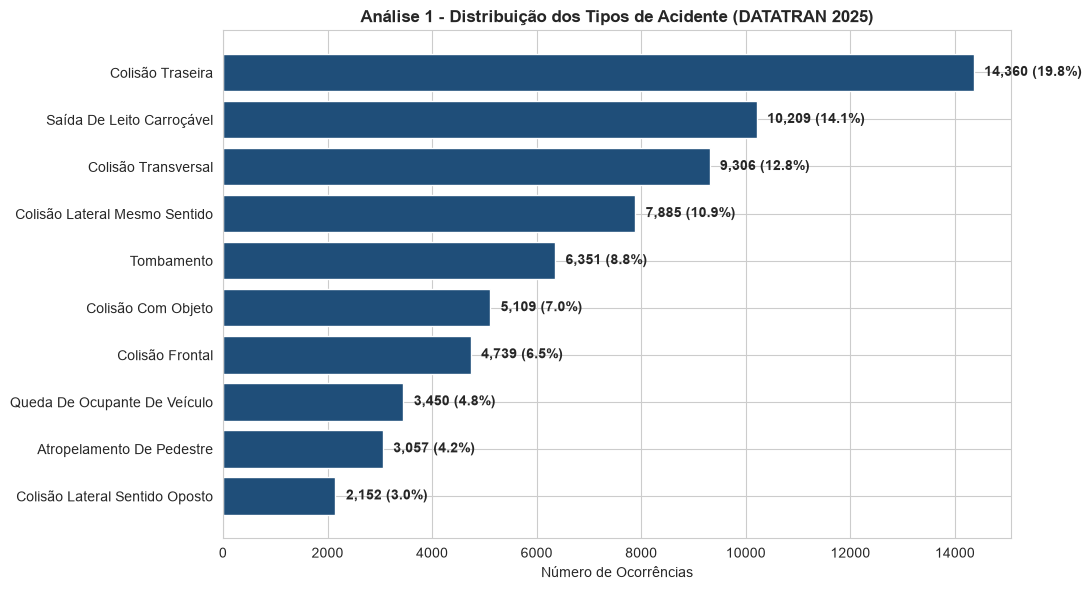

In [40]:
# Análise 1 
# Prepara dados
df['tipo_acidente'] = df['tipo_acidente'].astype(str).str.strip().str.lower()
tipos = df['tipo_acidente'].value_counts()

df_tipos = pd.DataFrame({
    'quantidade': tipos,
    'percentual': (tipos / len(df) * 100).round(1)
})

# Plota Top 10 horizontal
df_plot = df_tipos.sort_values('quantidade', ascending=True).tail(10)
df_plot.index = df_plot.index.str.title()

plt.figure(figsize=(11,6))
sns.set_style("whitegrid")
bars = plt.barh(df_plot.index, df_plot['quantidade'], color='#1f4e79')

# coloca o % 
for i, (qtd, pct) in enumerate(zip(df_plot['quantidade'], df_plot['percentual'])):
    plt.text(qtd + 200, i, f'{qtd:,} ({pct}%)', va='center', fontsize=10, fontweight='bold')

plt.title('Análise 1 - Distribuição dos Tipos de Acidente (DATATRAN 2025)', fontweight='bold')
plt.xlabel('Número de Ocorrências')
plt.tight_layout()
plt.show()

## 📝 Documentação — Análise 1 — Tipos de Acidente

**Resultados:** Os 3 tipos mais frequentes são Colisão Traseira (19,8%), Saída de Leito Carroçável (14,1%) e Colisão Transversal (12,8%), somando 46,7% de todos os 72.529 acidentes analisados.

**Insights:**
- Colisões (traseira + transversal + laterais) representam 56,4% dos casos, indicando forte relação com falta de atenção e desrespeito à distância de segurança.
- Saída de leito e tombamento (22,8% juntos) sugerem perda de controle, possivelmente associada à velocidade e fadiga.
    
**Ação recomendada:** Campanhas focadas em direção defensiva e alerta sobre frenagem teriam maior impacto na redução de sinistros, alinhado ao anuário da PRF 2025.

# 📍 Análise 2 — Acidentes por Estado
**Objetivo:** descobrir quais estados concentram mais acidentes e identificar padrões regionais.

In [11]:
# Quantidade de acidentes por estado
df['uf'].value_counts()

uf
MG    9570
SC    8186
PR    7630
RJ    6428
RS    4899
SP    4683
BA    4108
GO    3196
PE    3013
ES    2642
MT    2636
PB    1978
MS    1654
RN    1648
PI    1490
RO    1452
CE    1302
MA    1262
PA    1117
DF    1011
TO     677
AL     629
SE     589
AC     280
AP     169
RR     142
AM     138
Name: count, dtype: int64

In [12]:
# Percentual de acidentes por estado
(df['uf'].value_counts(normalize=True) * 100).round(2)

uf
MG    13.19
SC    11.29
PR    10.52
RJ     8.86
RS     6.75
SP     6.46
BA     5.66
GO     4.41
PE     4.15
ES     3.64
MT     3.63
PB     2.73
MS     2.28
RN     2.27
PI     2.05
RO     2.00
CE     1.80
MA     1.74
PA     1.54
DF     1.39
TO     0.93
AL     0.87
SE     0.81
AC     0.39
AP     0.23
RR     0.20
AM     0.19
Name: proportion, dtype: float64

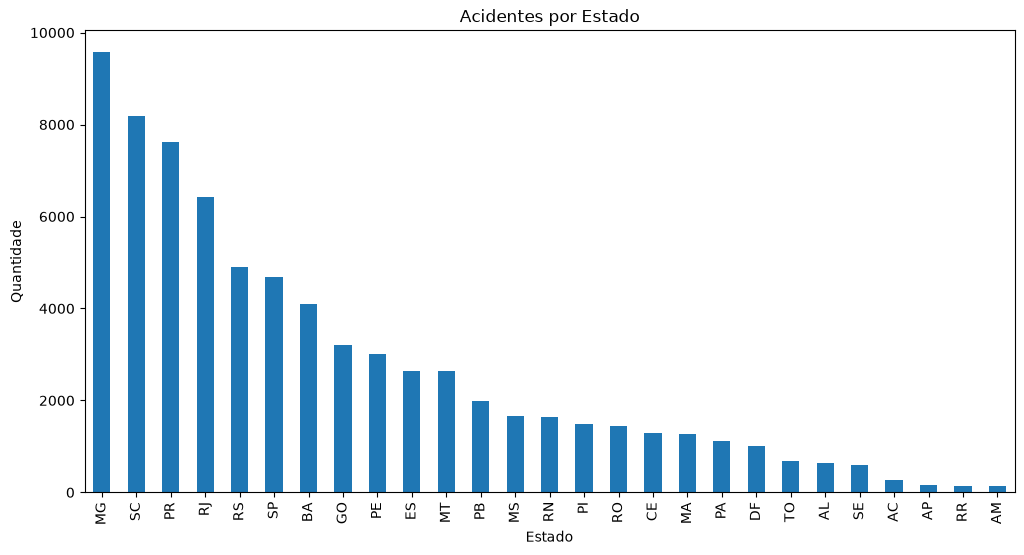

In [13]:
# Gráfico de barras: ranking de acidentes por estado
df['uf'].value_counts().plot(kind='bar', figsize=(12, 6))
plt.title('Acidentes por Estado')
plt.xlabel('Estado')
plt.ylabel('Quantidade')
plt.show()

In [14]:
# Ranking dos 10 estados com mais acidentes
df['uf'].value_counts().head(10)

uf
MG    9570
SC    8186
PR    7630
RJ    6428
RS    4899
SP    4683
BA    4108
GO    3196
PE    3013
ES    2642
Name: count, dtype: int64

### 📝 Documentação — Análise 2

- **Estados que lideram:** Minas Gerais (9.570 acidentes, 13,2%), Santa Catarina (8.186, 11,3%) e Paraná (7.630, 10,5%). Em seguida vêm RJ, RS e SP.
- **Concentração regional:** os 10 primeiros estados somam cerca de 75% de todos os acidentes. Sudeste (MG, RJ, SP, ES) e Sul (SC, PR, RS) juntos reúnem a maior parte dos registros: o Sudeste com cerca de 32% e o Sul com cerca de 29% entre esses estados.
- **Possíveis explicações:** extensão e movimento da malha rodoviária federal, grande frota de veículos e importância logística dessas regiões, com rodovias de alto tráfego como a BR-116, BR-101 e BR-381.
- **Observações relevantes:** Santa Catarina e Paraná aparecem acima de SP, que tem a maior frota do país. Isso sugere que o volume de acidentes registrados pela PRF depende mais da malha federal de cada estado do que da população. Por isso, estados com mais acidentes não são necessariamente os mais perigosos proporcionalmente.

# 🕒 Análise 3 — Horário e Período do Dia
**Objetivo:** entender quando os acidentes acontecem: madrugada, manhã, tarde ou noite.

In [15]:
# 'horario' vem do CSV como texto; convertemos para datetime para usar .dt.hour
df['horario'] = pd.to_datetime(df['horario'], format='%H:%M:%S', errors='coerce')
df['horario'].isna().sum()

np.int64(0)

In [16]:
# Distribuição dos acidentes por hora
df['horario'].dt.hour.value_counts().sort_index()

horario
0     1508
1     1291
2     1160
3     1263
4     1595
5     2090
6     3169
7     4583
8     3765
9     3108
10    3069
11    3165
12    3103
13    3141
14    3434
15    3690
16    4089
17    4845
18    5398
19    4646
20    3429
21    2737
22    2395
23    1856
Name: count, dtype: int64

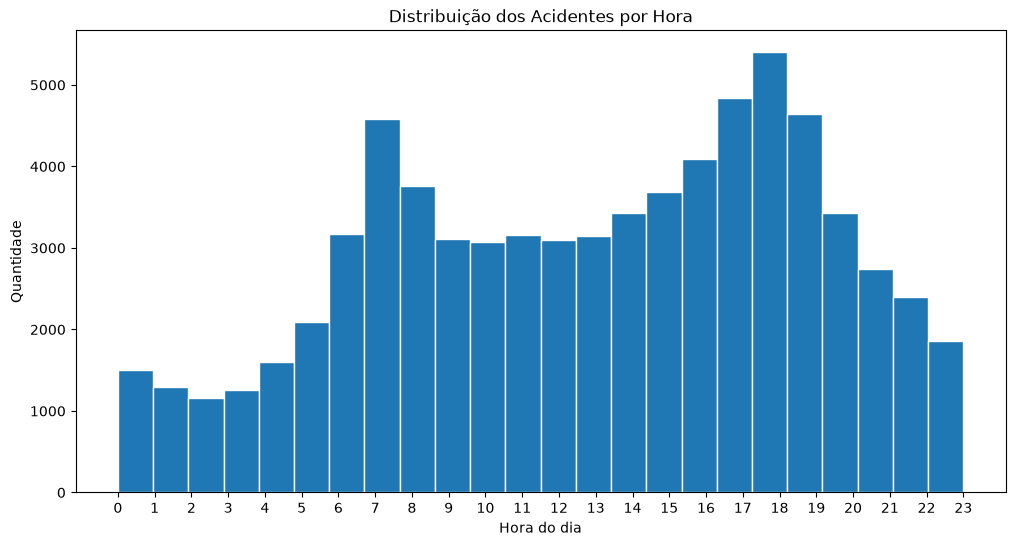

In [17]:
# Histograma dos horários
df['horario'].dt.hour.plot(kind='hist', bins=24, figsize=(12, 6), edgecolor='white')
plt.title('Distribuição dos Acidentes por Hora')
plt.xlabel('Hora do dia')
plt.ylabel('Quantidade')
plt.xticks(range(0, 24))
plt.show()

In [18]:
# Coluna 'periodo_dia' (colega 2). Se ainda não existir no seu notebook, cria uma equivalente:
# madrugada (0h-5h), manhã (6h-11h), tarde (12h-17h), noite (18h-23h)
if 'periodo_dia' not in df.columns:
    df['periodo_dia'] = pd.cut(
        df['horario'].dt.hour,
        bins=[-1, 5, 11, 17, 23],
        labels=['madrugada', 'manhã', 'tarde', 'noite']
    )

df['periodo_dia'].value_counts()

periodo_dia
tarde        22302
manhã        20859
noite        20461
madrugada     8907
Name: count, dtype: int64

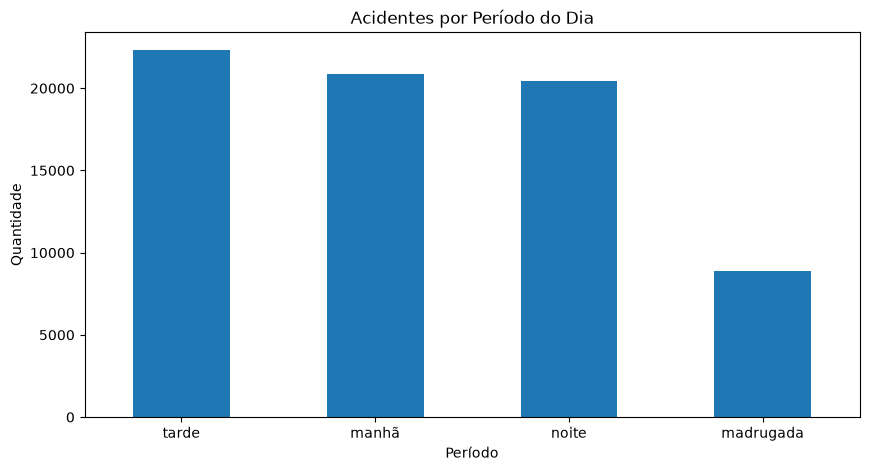

In [19]:
# Gráfico por período do dia
df['periodo_dia'].value_counts().plot(kind='bar', figsize=(10, 5))
plt.title('Acidentes por Período do Dia')
plt.xlabel('Período')
plt.ylabel('Quantidade')
plt.xticks(rotation=0)
plt.show()

### 📝 Documentação — Análise 3

- **Período com mais acidentes:** a tarde lidera (22.302 acidentes, 30,7%), seguida de perto pela manhã (20.859, 28,8%) e pela noite (20.461, 28,2%). A madrugada tem o menor volume (8.907, 12,3%).
- **Picos de horário:** o maior pico é às 18h (5.398 acidentes), seguido de 17h (4.845), 19h (4.646) e 7h (4.583). Há um pico menor no início da manhã e um mais forte no fim da tarde. O menor volume ocorre às 2h (1.160).
- **Possíveis hipóteses:** os picos coincidem com os horários de deslocamento entre casa e trabalho, com mais veículos na pista, além de cansaço ao fim do dia e menor luminosidade no começo da noite.
- **Relação com o fluxo de veículos:** o número de acidentes acompanha o movimento nas rodovias: cai na madrugada, quando há menos tráfego, e sobe nos horários de maior fluxo. A madrugada, mesmo com menos acidentes, pode ter maior gravidade proporcional, o que seria um ponto interessante de investigar.